# Part 4: Degree-Based SIR Models

## Capturing Heterogeneity Analytically

---

## The Degree Problem

Network SIR models are great, but they have limitations:
- **Computationally expensive** for large networks
- **Stochastic** — need many runs for statistics
- **Hard to analyze** mathematically

### Key Insight

In network models, **degree matters**:
- High-degree nodes (hubs) drive epidemics
- Low-degree nodes are less important

### The Question
Can we capture degree heterogeneity **analytically** without simulating the full network?

**Yes!** → **Degree-based mean-field models**

In [1]:
# Setup
import sys
sys.path.append('../src')

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from degree_sir import (
    compute_degree_distribution,
    simulate_degree_model,
    aggregate_by_degree,
    extract_degree_classes,
    plot_degree_distribution,
    plot_infection_by_degree
)
from network_sir import generate_random_graph, generate_scale_free, NetworkSIR

np.random.seed(42)
print("✓ Setup complete")

✓ Setup complete


## 4.1 Degree Distribution

### Definition
The **degree distribution** P(k) is the probability that a randomly chosen node has degree k.

### Key Statistics
- **Mean degree**: ⟨k⟩ = Σ k·P(k)
- **Second moment**: ⟨k²⟩ = Σ k²·P(k)

### Why It Matters
The shape of P(k) determines epidemic dynamics:
- **Poisson** (random graphs): narrow, homogeneous
- **Power-law** (scale-free): broad, heterogeneous with hubs

## Figure 16: Poisson Degree Distribution (Random Graph)

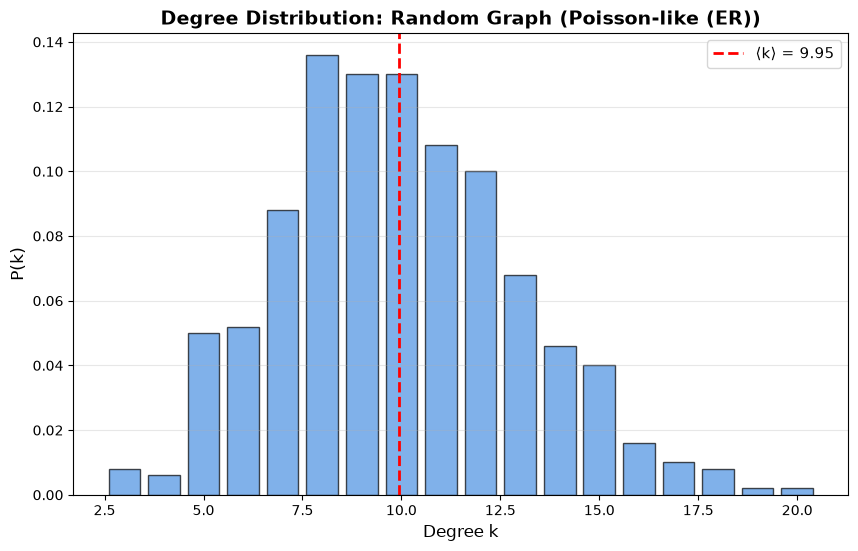

Random Graph:
  ⟨k⟩ = 9.95
  ⟨k²⟩ = 107.91
  ⟨k²⟩/⟨k⟩ = 10.85


In [2]:
# Create random (ER) graph
G_er = generate_random_graph(n=500, p=0.02)
k_vals_er, P_k_er = compute_degree_distribution(G_er)

fig, ax = plt.subplots(figsize=(10, 6))
plot_degree_distribution(k_vals_er, P_k_er, 
                        title="Degree Distribution: Random Graph",
                        distribution_type="Poisson-like (ER)", ax=ax)
plt.show()

mean_k = np.sum(k_vals_er * P_k_er)
k2 = np.sum(k_vals_er**2 * P_k_er)
print(f"Random Graph:")
print(f"  ⟨k⟩ = {mean_k:.2f}")
print(f"  ⟨k²⟩ = {k2:.2f}")
print(f"  ⟨k²⟩/⟨k⟩ = {k2/mean_k:.2f}")

## Figure 17: Power-Law Degree Distribution (Scale-Free)

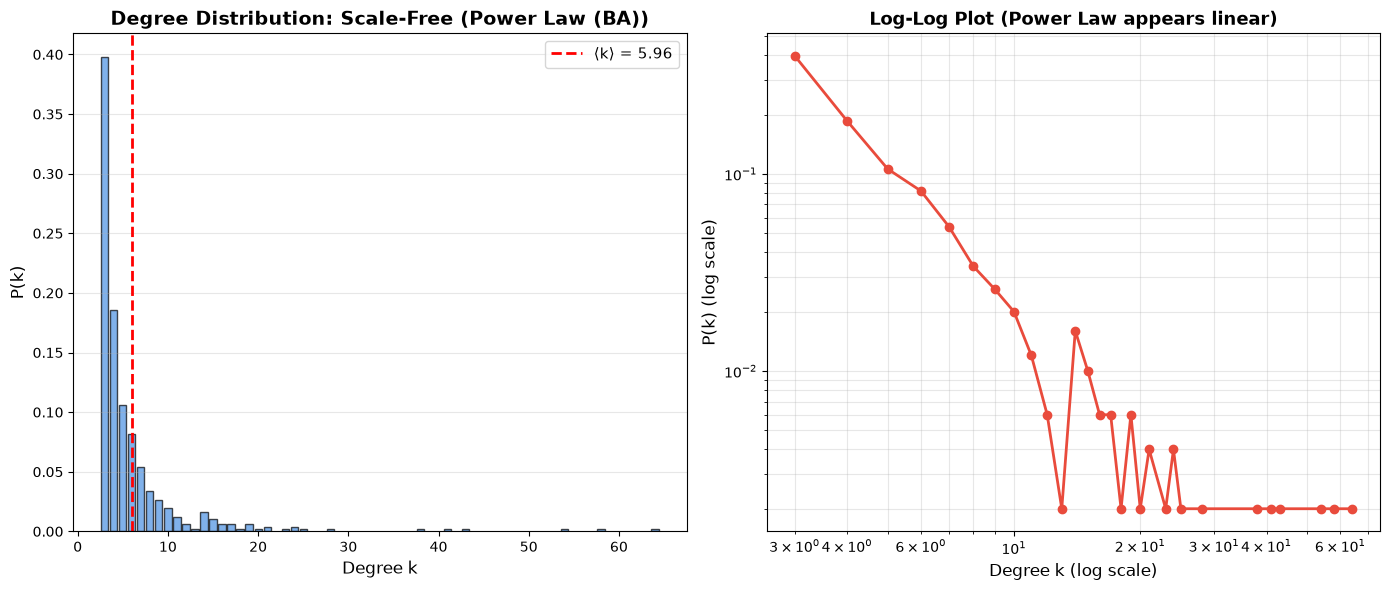

Scale-Free Graph:
  ⟨k⟩ = 5.96
  ⟨k²⟩ = 74.66
  ⟨k²⟩/⟨k⟩ = 12.52  ← Much larger than random graph!
  Max degree: 64 (hubs present)


In [3]:
# Create scale-free graph
G_sf = generate_scale_free(n=500, m=3)
k_vals_sf, P_k_sf = compute_degree_distribution(G_sf)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Linear scale
plot_degree_distribution(k_vals_sf, P_k_sf,
                        title="Degree Distribution: Scale-Free",
                        distribution_type="Power Law (BA)", ax=ax1)

# Log-log scale
mask = (k_vals_sf > 0) & (P_k_sf > 0)
ax2.loglog(k_vals_sf[mask], P_k_sf[mask], 'o-', 
          markersize=6, linewidth=2, color='#E94B3C')
ax2.set_xlabel('Degree k (log scale)', fontsize=12)
ax2.set_ylabel('P(k) (log scale)', fontsize=12)
ax2.set_title('Log-Log Plot (Power Law appears linear)', 
             fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3, which='both')

plt.tight_layout()
plt.show()

mean_k = np.sum(k_vals_sf * P_k_sf)
k2 = np.sum(k_vals_sf**2 * P_k_sf)
print(f"Scale-Free Graph:")
print(f"  ⟨k⟩ = {mean_k:.2f}")
print(f"  ⟨k²⟩ = {k2:.2f}")
print(f"  ⟨k²⟩/⟨k⟩ = {k2/mean_k:.2f}  ← Much larger than random graph!")
print(f"  Max degree: {k_vals_sf.max()} (hubs present)")

## 4.2 Degree-Based SIR Model

### Key Idea
Group nodes by their degree into **degree classes**:
- S_k = fraction of degree-k nodes that are susceptible
- I_k = fraction of degree-k nodes that are infected
- R_k = fraction of degree-k nodes that are recovered

### The Equations

$$\frac{dS_k}{dt} = -\beta k S_k \theta$$

$$\frac{dI_k}{dt} = \beta k S_k \theta - \gamma I_k$$

$$\frac{dR_k}{dt} = \gamma I_k$$

### What is θ (theta)?

**θ** = probability that a randomly chosen edge leads to an infected node

$$\theta = \frac{1}{\langle k \rangle} \sum_k k \cdot P(k) \cdot I_k$$

This couples all degree classes together.

## Simulating Degree-Based Models

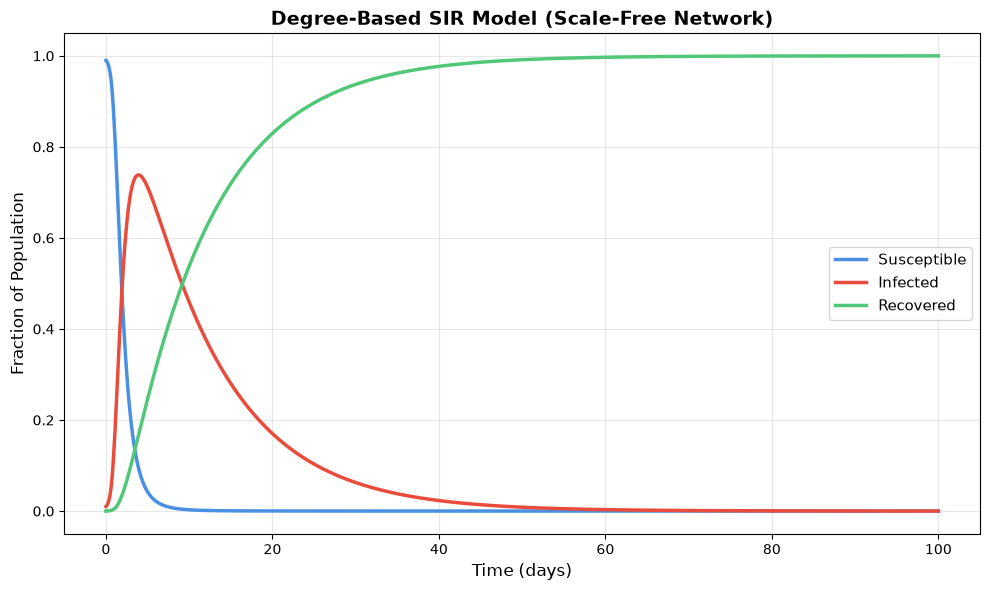

Mean degree: 5.98
Final fraction infected: 99.99%


In [4]:
# Use degree distribution from scale-free network
G = generate_scale_free(n=1000, m=3)
k_values, P_k = compute_degree_distribution(G)

# Simulate degree-based model
solution, mean_k = simulate_degree_model(
    beta=0.3,
    gamma=0.1,
    k_values=k_values,
    P_k=P_k,
    I0_k=None,  # Small uniform infection
    t_span=(0, 100)
)

# Extract and aggregate
N_classes = len(k_values)
S_total, I_total, R_total = aggregate_by_degree(solution, P_k, N_classes)

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
t = solution.t

ax.plot(t, S_total, label='Susceptible', linewidth=2.5, color='#4A90E2')
ax.plot(t, I_total, label='Infected', linewidth=2.5, color='#E94B3C')
ax.plot(t, R_total, label='Recovered', linewidth=2.5, color='#50C878')

ax.set_xlabel('Time (days)', fontsize=12)
ax.set_ylabel('Fraction of Population', fontsize=12)
ax.set_title('Degree-Based SIR Model (Scale-Free Network)', 
            fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Mean degree: {mean_k:.2f}")
print(f"Final fraction infected: {R_total[-1]:.2%}")

## Figure 18: ER vs Scale-Free Comparison

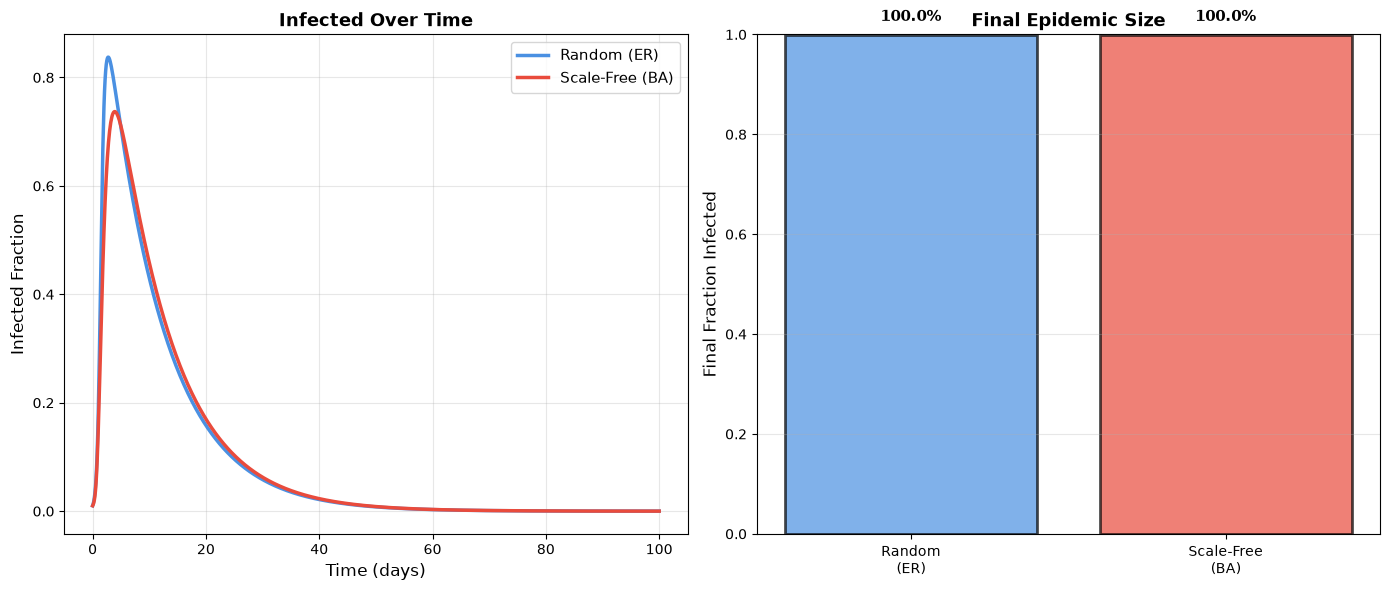

Random Graph:     ⟨k⟩=10.09, final infected=100.0%
Scale-Free Graph: ⟨k⟩=5.98, final infected=100.0%

Scale-free networks are MORE vulnerable despite similar average degree!


In [5]:
# Compare ER and SF networks using degree-based model
beta, gamma = 0.3, 0.1

# ER network
G_er = generate_random_graph(n=1000, p=0.01)
k_er, P_er = compute_degree_distribution(G_er)
sol_er, mean_k_er = simulate_degree_model(beta, gamma, k_er, P_er, t_span=(0, 100))
S_er, I_er, R_er = aggregate_by_degree(sol_er, P_er, len(k_er))

# SF network
G_sf = generate_scale_free(n=1000, m=3)
k_sf, P_sf = compute_degree_distribution(G_sf)
sol_sf, mean_k_sf = simulate_degree_model(beta, gamma, k_sf, P_sf, t_span=(0, 100))
S_sf, I_sf, R_sf = aggregate_by_degree(sol_sf, P_sf, len(k_sf))

# Plot comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Infected comparison
ax1.plot(sol_er.t, I_er, label='Random (ER)', linewidth=2.5, color='#4A90E2')
ax1.plot(sol_sf.t, I_sf, label='Scale-Free (BA)', linewidth=2.5, color='#E94B3C')
ax1.set_xlabel('Time (days)', fontsize=12)
ax1.set_ylabel('Infected Fraction', fontsize=12)
ax1.set_title('Infected Over Time', fontsize=13, fontweight='bold')
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)

# Final size comparison
networks = ['Random\n(ER)', 'Scale-Free\n(BA)']
final_sizes = [R_er[-1], R_sf[-1]]
colors_bar = ['#4A90E2', '#E94B3C']

bars = ax2.bar(networks, final_sizes, color=colors_bar, alpha=0.7, edgecolor='black', linewidth=2)
ax2.set_ylabel('Final Fraction Infected', fontsize=12)
ax2.set_title('Final Epidemic Size', fontsize=13, fontweight='bold')
ax2.set_ylim(0, 1)
ax2.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for bar, val in zip(bars, final_sizes):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + 0.02,
            f'{val:.1%}', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"Random Graph:     ⟨k⟩={mean_k_er:.2f}, final infected={R_er[-1]:.1%}")
print(f"Scale-Free Graph: ⟨k⟩={mean_k_sf:.2f}, final infected={R_sf[-1]:.1%}")
print(f"\nScale-free networks are MORE vulnerable despite similar average degree!")

## Figure 19: Infection by Degree Class

How does infection spread across different degree classes?

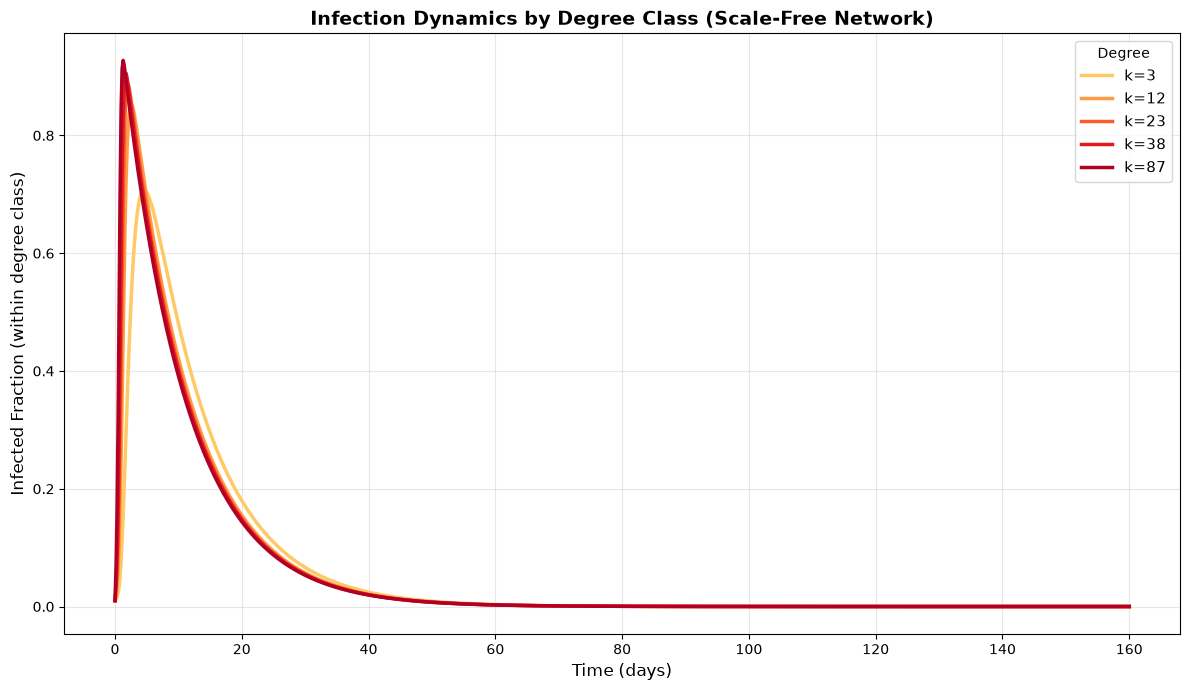

Key observation: Higher-degree nodes (hubs) get infected earlier and more


In [6]:
# Use scale-free network
G = generate_scale_free(n=1000, m=3)
k_values, P_k = compute_degree_distribution(G)
solution, mean_k = simulate_degree_model(beta=0.3, gamma=0.1, k_values=k_values, P_k=P_k)

# Extract degree classes
N_classes = len(k_values)
S_k, I_k, R_k = extract_degree_classes(solution, N_classes)

# Plot infection for selected degree classes
fig, ax = plt.subplots(figsize=(12, 7))

# Select representative degrees
degree_indices = [0, N_classes//4, N_classes//2, 3*N_classes//4, N_classes-1]
degree_indices = [i for i in degree_indices if i < N_classes]
colors_deg = plt.cm.YlOrRd(np.linspace(0.3, 0.9, len(degree_indices)))

for idx, color in zip(degree_indices, colors_deg):
    k = k_values[idx]
    ax.plot(solution.t, I_k[idx, :], label=f'k={k:.0f}', linewidth=2.5, color=color)

ax.set_xlabel('Time (days)', fontsize=12)
ax.set_ylabel('Infected Fraction (within degree class)', fontsize=12)
ax.set_title('Infection Dynamics by Degree Class (Scale-Free Network)', 
            fontsize=14, fontweight='bold')
ax.legend(fontsize=11, title='Degree')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Key observation: Higher-degree nodes (hubs) get infected earlier and more")

## Figure 20: Theta (θ) Evolution

Track how the edge-to-infected probability evolves over time.

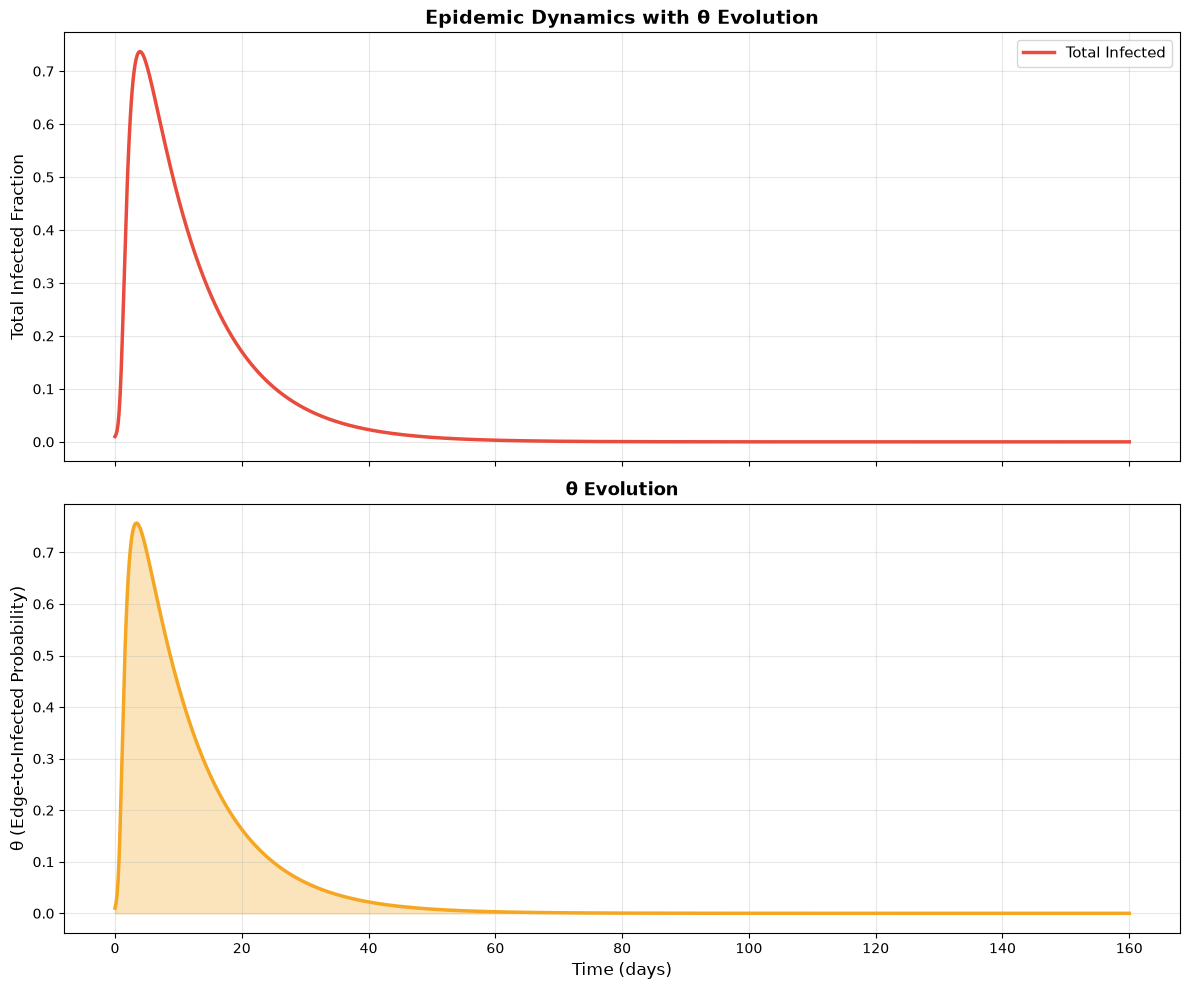

Peak θ: 0.757 (maximum infection risk per edge)
θ tracks the infected fraction but weighted by degree distribution


In [7]:
# Compute theta over time
from degree_sir import compute_theta

theta_vals = []
for t_idx in range(len(solution.t)):
    I_k_t = I_k[:, t_idx]
    theta = compute_theta(I_k_t, P_k, k_values, mean_k)
    theta_vals.append(theta)

theta_vals = np.array(theta_vals)

# Plot
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

# Top: Infected fraction
S_total, I_total, R_total = aggregate_by_degree(solution, P_k, N_classes)
ax1.plot(solution.t, I_total, linewidth=2.5, color='#E94B3C', label='Total Infected')
ax1.set_ylabel('Total Infected Fraction', fontsize=12)
ax1.set_title('Epidemic Dynamics with θ Evolution', fontsize=14, fontweight='bold')
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)

# Bottom: Theta
ax2.plot(solution.t, theta_vals, linewidth=2.5, color='#F5A623')
ax2.fill_between(solution.t, 0, theta_vals, alpha=0.3, color='#F5A623')
ax2.set_xlabel('Time (days)', fontsize=12)
ax2.set_ylabel('θ (Edge-to-Infected Probability)', fontsize=12)
ax2.set_title('θ Evolution', fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Peak θ: {theta_vals.max():.3f} (maximum infection risk per edge)")
print(f"θ tracks the infected fraction but weighted by degree distribution")

## 4.3 Epidemic Threshold

### Classical SIR Threshold
R₀ = β/γ > 1 required for epidemic

### Degree-Based Threshold
For networks:

$$R_0 = \frac{\beta}{\gamma} \cdot \frac{\langle k^2 \rangle}{\langle k \rangle}$$

### Key Insight
The ratio **⟨k²⟩/⟨k⟩** matters!

- **Random graphs**: ⟨k²⟩/⟨k⟩ ≈ ⟨k⟩ (modest)
- **Scale-free graphs**: ⟨k²⟩/⟨k⟩ >> ⟨k⟩ (large, can be unbounded!)

### Implication
**Scale-free networks have NO epidemic threshold** if the degree distribution is unbounded (infinite ⟨k²⟩).

Even diseases with low transmission can cause epidemics on scale-free networks!

In [8]:
# Compare thresholds
print("Epidemic Threshold Analysis\n" + "="*50)

# Random graph
G_er = generate_random_graph(n=1000, p=0.01)
k_er, P_er = compute_degree_distribution(G_er)
mean_k_er = np.sum(k_er * P_er)
k2_er = np.sum(k_er**2 * P_er)
R0_network_er = (0.3/0.1) * (k2_er / mean_k_er)

print(f"Random Graph (ER):")
print(f"  ⟨k⟩ = {mean_k_er:.2f}")
print(f"  ⟨k²⟩ = {k2_er:.2f}")
print(f"  ⟨k²⟩/⟨k⟩ = {k2_er/mean_k_er:.2f}")
print(f"  Network R₀ = {R0_network_er:.2f}")
print()

# Scale-free graph
G_sf = generate_scale_free(n=1000, m=3)
k_sf, P_sf = compute_degree_distribution(G_sf)
mean_k_sf = np.sum(k_sf * P_sf)
k2_sf = np.sum(k_sf**2 * P_sf)
R0_network_sf = (0.3/0.1) * (k2_sf / mean_k_sf)

print(f"Scale-Free Graph (BA):")
print(f"  ⟨k⟩ = {mean_k_sf:.2f}")
print(f"  ⟨k²⟩ = {k2_sf:.2f}")
print(f"  ⟨k²⟩/⟨k⟩ = {k2_sf/mean_k_sf:.2f}  ← Much larger!")
print(f"  Network R₀ = {R0_network_sf:.2f}")
print()

print("Conclusion:")
print("Even with similar average degree, scale-free networks")
print("are much more vulnerable to epidemic outbreaks!")

Epidemic Threshold Analysis
Random Graph (ER):
  ⟨k⟩ = 10.24
  ⟨k²⟩ = 115.18
  ⟨k²⟩/⟨k⟩ = 11.25
  Network R₀ = 33.75

Scale-Free Graph (BA):
  ⟨k⟩ = 5.98
  ⟨k²⟩ = 92.46
  ⟨k²⟩/⟨k⟩ = 15.46  ← Much larger!
  Network R₀ = 46.37

Conclusion:
Even with similar average degree, scale-free networks
are much more vulnerable to epidemic outbreaks!


## Summary

### What We Learned

1. **Degree-based models bridge network and mean-field**
   - Capture heterogeneity analytically
   - Much faster than full network simulations
   - Deterministic (no stochasticity)

2. **Degree distribution matters**
   - Poisson (random) → relatively homogeneous
   - Power-law (scale-free) → highly heterogeneous
   - Hubs drive epidemics

3. **Higher-degree nodes infected first**
   - Hubs act as super-spreaders
   - Infection spreads faster through high-degree classes

4. **⟨k²⟩/⟨k⟩ determines vulnerability**
   - Larger ratio → more vulnerable
   - Scale-free networks can have no epidemic threshold

### Advantages
- ✅ Captures heterogeneity
- ✅ Analytically tractable
- ✅ Computationally efficient
- ✅ Deterministic (no Monte Carlo averaging needed)

### Limitations
- Still a **mean-field** approximation (assumes random mixing within degree classes)
- No **spatial structure**
- No **individual-level** behaviors
- Assumes **degree is the only heterogeneity**

---

## What's Still Missing

Both network and degree-based models lack:
- **Spatial dynamics** (agents moving in space)
- **Individual behaviors** (complex rules)
- **Stochasticity at small scales**

**Next**: We move to **Agent-Based Models** for the most flexible approach.